In [9]:
%matplotlib widget
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy.integrate import cumulative_trapezoid
from scipy.interpolate import interp1d

from ecm_model import ECM
from module_model import Module


In [10]:
# Create current signal
c_rate = [np.zeros(300)]
k = int(0.8 * 3600)
for cycle in range(3):
    c_rate.append(np.ones(k))
    c_rate.append(np.zeros(300))
    c_rate.append(np.ones(k) * -1)
c_rate.append(np.zeros(300))
c_rate = np.hstack(c_rate)[None, :]
t = np.arange(c_rate.size)

In [11]:
ecm_parameters = {
    "Initial State of Charge / 1": 0.1,
    "Mean State of Health / 1": 1.0,
    "Stdev State of Health / 1": 0.05,
    "Mean State of Resistance / 1": 1.0,
    "Stdev State of Resistance / 1": 0.2,
    "Nominal Capacity / Ah": 5.0,
    "Timeconstant hysteresis / 1": 0.3,
}

cells_in_parallel = 24
cells_in_series = 6

module_parameters = {
    "Positive terminal resistance / Ohm": np.random.normal(
        1e-4,
        1e-5,
        cells_in_parallel,
    ).clip(min=1e-9, max=1e-1),
    "Negative terminal resistance / Ohm": np.random.normal(
        1e-4,
        1e-5,
        cells_in_parallel,
    ).clip(min=1e-9, max=1e-1),
    "Series resistance / Ohm": np.random.normal(
        1e-4,
        1e-5,
        (cells_in_series, cells_in_parallel),
    ).clip(min=1e-9, max=1e-1),
    "Parallel resistance / Ohm": np.random.normal(
        1e-1,
        1e-2,
        (cells_in_series + 1, cells_in_parallel - 1),
    ).clip(min=1e-9, max=1e-1),
}

In [12]:
ecm = ECM(parameters=ecm_parameters, parameters_source="gitt")
sim_cell = ecm.simulate(t, c_rate * ecm.parameters["Nominal Capacity / Ah"])

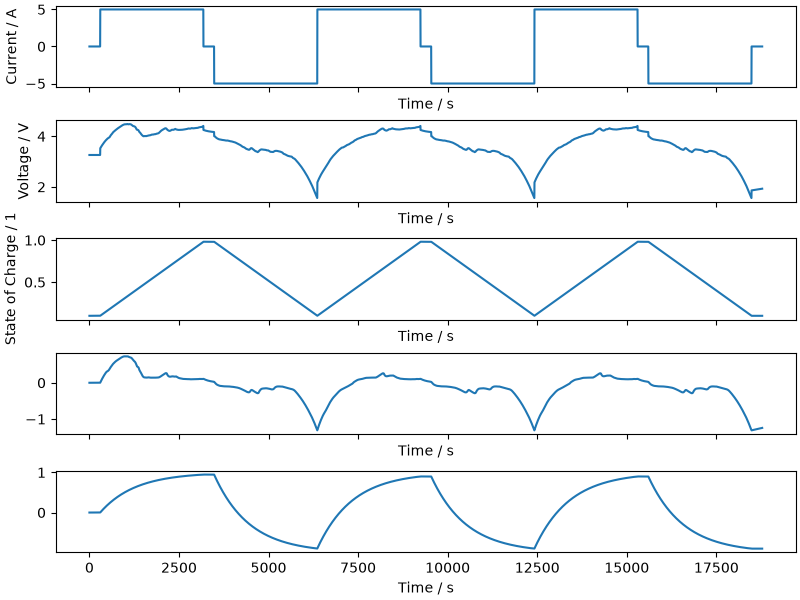

In [13]:
fig, axs = plt.subplots(5, 1, sharex=True, figsize=(8, 6), constrained_layout=True)
axs[0].plot(t, c_rate[0] * ecm.parameters["Nominal Capacity / Ah"], label="Current")
axs[1].plot(t, sim_cell.voltage[0], label="Voltage")
axs[2].plot(t, sim_cell.soc[0], label="State of Charge")
axs[3].plot(t, sim_cell.polarization[0], label="Polarization")
axs[4].plot(t, sim_cell.hysteresis[0], label="Hysteresis")

axs[0].set_ylabel("Current / A")
axs[1].set_ylabel("Voltage / V")
axs[2].set_ylabel("State of Charge / 1")
for ax in axs:
    ax.set_xlabel("Time / s")

In [14]:
module = Module(
    cells_in_parallel=cells_in_parallel,
    cells_in_series=cells_in_series,
    cell_parameters=ecm_parameters,
    module_parameters=module_parameters,
    parameters_source="gitt",
)
sim_module = module.simulate(
    t, c_rate * module.module_parameters["Nominal Capacity / Ah"]
)

  0%|          | 1/18780 [00:00<?, ?it/s]

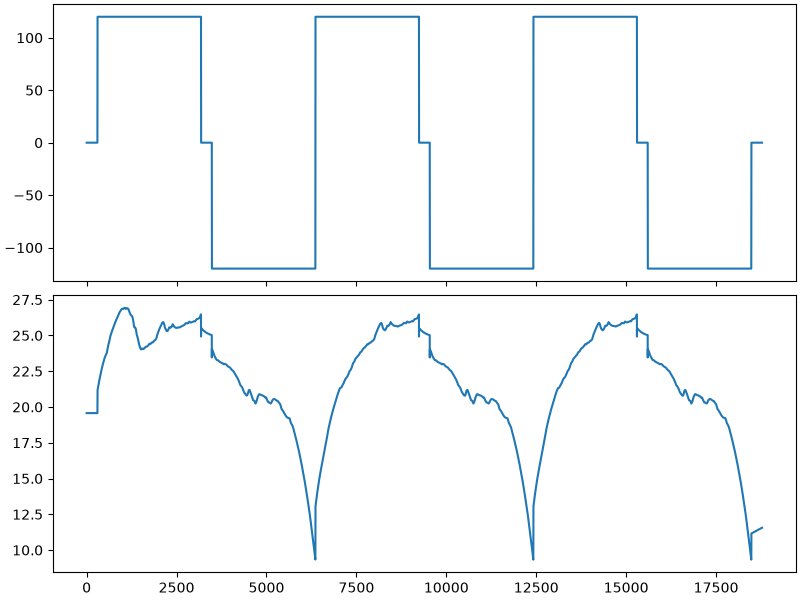

In [15]:
fig, axs = plt.subplots(2, 1, sharex=True, figsize=(8, 6), constrained_layout=True)
axs[0].plot(
    t, c_rate[0] * module.module_parameters["Nominal Capacity / Ah"], label="Current"
)
axs[1].plot(t, sim_module.module_voltage, label="Voltage")

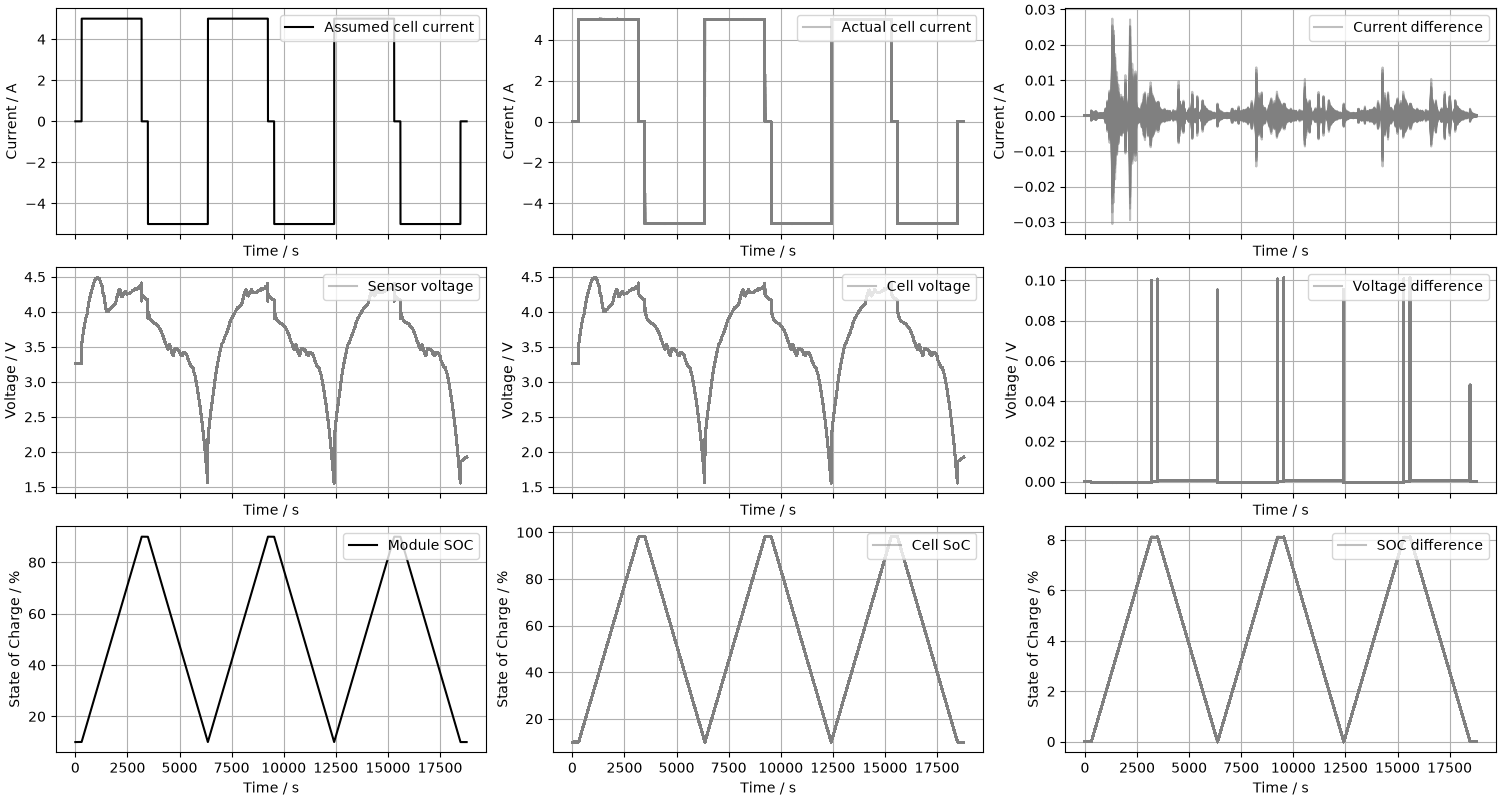

In [16]:
fig, axs = plt.subplots(3, 3, sharex=True, figsize=(15, 8), constrained_layout=True)

axs[0, 0].plot(
    t,
    sim_module.module_current[0] / module.cells_in_parallel,
    label="Assumed cell current",
    color="k",
)

lines = axs[0, 1].plot(
    t,
    sim_module.cell_current.reshape((-1, t.size)).T,
    label="Actual cell current",
    color="gray",
    alpha=0.5,
)
for line in lines[1:]:
    line.set_label("_nolegend_")

lines = axs[0, 2].plot(
    t,
    (sim_module.cell_current - sim_module.module_current / module.cells_in_parallel)
    .reshape(-1, t.size)
    .T,
    label="Current difference",
    color="gray",
    alpha=0.5,
)
for line in lines[1:]:
    line.set_label("_nolegend_")


lines = axs[1, 0].plot(
    t,
    sim_module.sensor_voltage.reshape((-1, t.size)).T,
    label="Sensor voltage",
    color="gray",
    alpha=0.5,
)
for line in lines[1:]:
    line.set_label("_nolegend_")
lines = axs[1, 1].plot(
    t,
    sim_module.cell_voltage.reshape((-1, t.size)).T,
    label="Cell voltage",
    color="gray",
    alpha=0.5,
)
for line in lines[1:]:
    line.set_label("_nolegend_")

lines = axs[1, 2].plot(
    t,
    (sim_module.cell_voltage - sim_module.sensor_voltage).reshape(-1, t.size).T,
    label="Voltage difference",
    color="gray",
    alpha=0.5,
)
for line in lines[1:]:
    line.set_label("_nolegend_")


_soc = (
    cumulative_trapezoid(
        sim_module.module_current[0]
        / module.module_parameters["Nominal Capacity / Ah"],
        t,
        initial=0,
    )
    / 3600
    + module.cell_parameters["Initial State of Charge / 1"]
)
axs[2, 0].plot(t, 100 * _soc, label="Module SOC", color="k")
lines = axs[2, 1].plot(
    t,
    100 * sim_module.cell_soc.reshape((-1, t.size)).T,
    label="Cell SoC",
    color="gray",
    alpha=0.5,
)
for line in lines[1:]:
    line.set_label("_nolegend_")

lines = axs[2, 2].plot(
    t,
    100 * (sim_module.cell_soc - _soc).reshape(-1, t.size).T,
    label="SOC difference",
    color="gray",
    alpha=0.5,
)
for line in lines[1:]:
    line.set_label("_nolegend_")

for ax in axs[0, :]:
    ax.set_ylabel("Current / A")
for ax in axs[1, :]:
    ax.set_ylabel("Voltage / V")
for ax in axs[2, :]:
    ax.set_ylabel("State of Charge / %")


for ax in axs.ravel():
    ax.set_xlabel("Time / s")
    ax.legend(loc="upper right")
    ax.grid(True)
fig.savefig("gitt_module_simulation.png", dpi=300, bbox_inches="tight")